Cell 1 — Import libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

print("All libraries imported successfully!")

All libraries imported successfully!


Cell 2 — Load the CSV file

You should see approximately 8,124 rows and 23 columns: one target column and 22 feature columns.

In [2]:
df = pd.read_csv("mushrooms.csv")

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (8124, 23)


,class,cap-shape,cap-surface,cap-color,bruises,odor,gill-attachment,gill-spacing,gill-size,gill-color,...,stalk-surface-below-ring,stalk-color-above-ring,stalk-color-below-ring,veil-type,veil-color,ring-number,ring-type,spore-print-color,population,habitat
0,p,x,s,n,t,p,f,c,n,k,...,s,w,w,p,w,o,p,k,s,u
1,e,x,s,y,t,a,f,c,b,k,...,s,w,w,p,w,o,p,n,n,g
2,e,b,s,w,t,l,f,c,b,n,...,s,w,w,p,w,o,p,n,n,m
3,p,x,y,w,t,p,f,c,n,n,...,s,w,w,p,w,o,p,k,s,u
4,e,x,s,g,f,n,f,w,b,k,...,s,w,w,p,w,o,e,n,a,g


Cell 3 — Explore the dataset

The target column is class:
- e = edible
- p = poisonous

In [3]:
print("Column names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

Column names:
['class', 'cap-shape', 'cap-surface', 'cap-color', 'bruises', 'odor', 'gill-attachment', 'gill-spacing', 'gill-size', 'gill-color', 'stalk-shape', 'stalk-root', 'stalk-surface-above-ring', 'stalk-surface-below-ring', 'stalk-color-above-ring', 'stalk-color-below-ring', 'veil-type', 'veil-color', 'ring-number', 'ring-type', 'spore-print-color', 'population', 'habitat']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8124 entries, 0 to 8123
Data columns (total 23 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   class                     8124 non-null   object
 1   cap-shape                 8124 non-null   object
 2   cap-surface               8124 non-null   object
 3   cap-color                 8124 non-null   object
 4   bruises                   8124 non-null   object
 5   odor                      8124 non-null   object
 6   gill-attachment           8124 non-null   object
 

Cell 4 — Visualize the target

This graph displays the number of edible and poisonous mushroom examples.

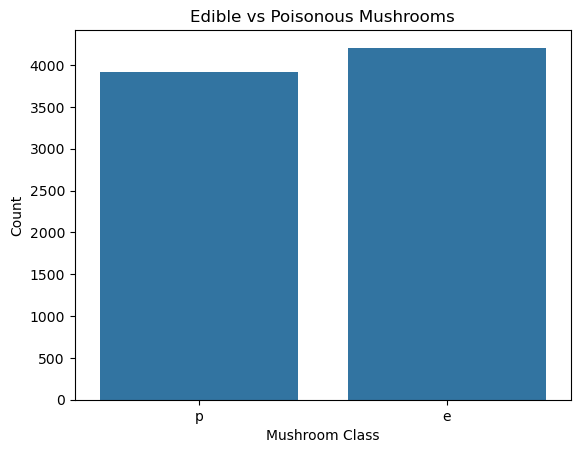

In [4]:
sns.countplot(data=df, x="class")

plt.title("Edible vs Poisonous Mushrooms")
plt.xlabel("Mushroom Class")
plt.ylabel("Count")
plt.show()

Cell 5 — Prepare features and target

All the mushroom features are categorical, so we must convert them into numerical values before training SVM.

Here, 0 represents edible and 1 represents poisonous.

In [5]:
X = df.drop(columns=["class"])
y = df["class"].map({"e": 0, "p": 1})

print("Features shape:", X.shape)
print("Target shape:", y.shape)

print("\nTarget values:")
print(y.value_counts())

Features shape: (8124, 22)
Target shape: (8124,)

Target values:
class
0    4208
1    3916
Name: count, dtype: int64


Cell 6 — Encode categorical features

We'll use one-hot encoding to convert categorical features into numerical columns.

In [6]:
X_encoded = pd.get_dummies(X, dtype=int)

print("Original features:", X.shape[1])
print("Encoded features:", X_encoded.shape[1])

display(X_encoded.head())

Original features: 22
Encoded features: 117


,cap-shape_b,cap-shape_c,cap-shape_f,cap-shape_k,cap-shape_s,cap-shape_x,cap-surface_f,cap-surface_g,cap-surface_s,cap-surface_y,...,population_s,population_v,population_y,habitat_d,habitat_g,habitat_l,habitat_m,habitat_p,habitat_u,habitat_w
0,0,0,0,0,0,1,0,0,1,0,...,1,0,0,0,0,0,0,0,1,0
1,0,0,0,0,0,1,0,0,1,0,...,0,0,0,0,1,0,0,0,0,0
2,1,0,0,0,0,0,0,0,1,0,...,0,0,0,0,0,0,1,0,0,0
3,0,0,0,0,0,1,0,0,0,1,...,1,0,0,0,0,0,0,0,1,0
4,0,0,0,0,0,1,0,0,1,0,...,0,0,0,0,1,0,0,0,0,0


Cell 7 — Split training and testing data

We use 80% of the data to train the model and 20% to test it.

In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    X_encoded,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training samples: 6499
Testing samples: 1625


Cell 8 — Train the SVM model


Why SVM? It learns a decision boundary that separates edible and poisonous mushroom examples using their encoded characteristics.

In [8]:
svm_model = Pipeline([
    ("scaler", StandardScaler()),
    ("svm", SVC(kernel="rbf", C=1.0, gamma="scale"))
])

svm_model.fit(X_train, y_train)

print("SVM model training completed!")

SVM model training completed!


Cell 9 — Test the model

Record the accuracy you actually obtain. Don't assume a result before running the code.

In [9]:
y_pred = svm_model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)

print(f"Test Accuracy: {accuracy * 100:.2f}%")

Test Accuracy: 99.88%


Cell 10 — Classification report

This provides precision, recall, and F1-score for each class.

In [10]:
print(classification_report(
    y_test,
    y_pred,
    target_names=["Edible", "Poisonous"],
    zero_division=0
))

              precision    recall  f1-score   support

      Edible       1.00      1.00      1.00       842
   Poisonous       1.00      1.00      1.00       783

    accuracy                           1.00      1625
   macro avg       1.00      1.00      1.00      1625
weighted avg       1.00      1.00      1.00      1625



Cell 11 — Confusion matrix

The confusion matrix shows correct predictions and mistakes made by the model.

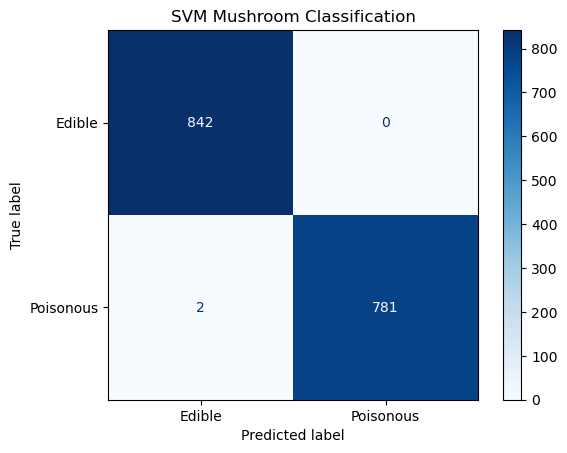

In [11]:
cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Edible", "Poisonous"]
)

disp.plot(cmap="Blues")
plt.title("SVM Mushroom Classification")
plt.show()

Cell 12 — Try one prediction

This tests the model on one example from the held-out test set.

Important: This is a learning project, not a tool for deciding whether a real mushroom is safe to eat.

In [12]:
sample = X_test.iloc[[0]]

prediction = svm_model.predict(sample)[0]

if prediction == 0:
    print("Predicted class: Edible")
else:
    print("Predicted class: Poisonous")

print("Actual class:", "Edible" if y_test.iloc[0] == 0 else "Poisonous")

Predicted class: Poisonous
Actual class: Poisonous




## Conclusion

In this project, I used SVM to predict whether mushrooms are edible or poisonous. I cleaned and prepared the data, trained the model, and tested its accuracy. This project helped me understand how SVM works for classification.